# La idea de la tarjeta de puntaje: peso de la evidencia, valor de información y puntos

**Pregunta:** ¿Puede un analista de crédito leer el riesgo de incumplimiento de una tarjeta desde una tabla impresa de puntos, y cuánto del poder de orden del modelo detrás de la tabla sobrevive al redondeo a puntos enteros?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el tema 01 (primeros pasos)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- decir qué miden el peso de la evidencia (WoE) y el valor de información (IV) de una variable en tramos, y calcular ambos desde los conteos de un tramo;
- explicar cómo un modelo logístico sobre WoE se convierte en una tabla de puntos, y qué significan los puntos para duplicar las probabilidades relativas (PDO);
- reconstruir la PD de una tarjeta solo desde su puntaje entero y ver qué cuesta el redondeo de los puntos;
- leer la discriminación y la tabla de grados de la tarjeta de puntaje en 9.000 tarjetas reservadas con el AUC, el KS y las pruebas por grado del motor.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation.calibration import pd_chi2_grades, pd_jeffreys_grades
from riskvalidation.validation.discrimination import auc_with_variance, cap_accuracy_ratio, disc_auc, disc_ks

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C01, la PD de tarjetas de crédito minoristas, tal como Contraste los versiona. Las 30.000 tarjetas vienen del archivo de tarjetas de crédito de Taiwán de UCI (Yeh, 2009; dueño: UCI Machine Learning Repository; CC BY 4.0, clase de licencia `mirror-allowed`; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). La cadena de cálculo las dividió una sola vez con una semilla fija: 16.800 tarjetas para ajustar la tarjeta de puntaje, 4.200 para calibrar a los retadores y una muestra reservada bloqueada de 9.000 tarjetas que ningún ajuste ha visto. Dos archivos versionados contienen lo que este notebook necesita, así que no ajusta nada y no requiere datos crudos:

- `data/derived/C01/models-taiwan.json`: la tarjeta de puntaje ajustada (peldaño P1): coeficientes, valores de información, escala y la tabla de puntos con los conteos de cada tramo en las 16.800 tarjetas de entrenamiento. Dueño: este repositorio.
- `data/derived/C01/holdout.json`: la tarjeta de puntaje sobre la muestra reservada: una muestra de 50 tarjetas con entradas crudas, puntos, puntaje y PD, la curva CAP y la tabla de 12 grados de las 9.000 tarjetas, y las filas de prueba versionadas.

La siguiente celda carga ambos archivos e imprime el tamaño de la tarjeta de puntaje.

In [2]:
# Cargar los dos archivos versionados del caso C01 (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
models = json.loads((derived / "models-taiwan.json").read_text(encoding="utf-8"))
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))
card = next(m for m in models["model"] if m["id"] == "P1-scorecard")["details"]
table = card["points_table"]
sample = holdout["outputs"]["sample"]
policy = rv.default_policy()
LIGHT = {"green": "verde", "amber": "ámbar", "red": "roja", "not_evaluated": "ninguna"}
print("tarjetas de entrenamiento:", models["fit"]["train_rows"], "| variables retenidas:", len(card["features"]))
print("filas de la tabla:", len(table))
print("calculado por riskvalidation", models["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

tarjetas de entrenamiento: 16800 | variables retenidas: 13
filas de la tabla: 95
calculado por riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: una variable en tramos y el peso de la evidencia de cada tramo

Una tarjeta de puntaje nunca usa una variable cruda. Corta cada una en pocos **tramos** ordenados, elegidos para que la tasa de incumplimiento suba (o baje) de manera sostenida de un tramo al siguiente y ningún tramo tenga menos del 5% de las tarjetas, y trabaja con el tramo en que cae la tarjeta. Un tramo es una fila de una tabla impresa: un analista de crédito puede leerla y un auditor puede verificarla. La variable con la señal más fuerte es `PAY_0`, el estado de pago del último mes (-1 pagado a tiempo, 1 un mes de atraso, 2 dos meses de atraso, y así sucesivamente). La siguiente celda toma sus tramos de la tabla de puntos de la tarjeta ajustada y calcula el peso de la evidencia de cada uno a partir de los conteos de incumplidores y de buenos pagadores. Con $r^{NE}_i / r^{NE}_T$ la proporción de todos los no eventos que caen en el tramo $i$ y $r^{E}_i / r^{E}_T$ la proporción de todos los eventos, el peso de la evidencia y el valor de información son (Navas-Palencia, 2020, sección 2.1)

$$\mathrm{WoE}_i = \ln\!\left(\frac{r_i^{NE} / r_T^{NE}}{r_i^{E} / r_T^{E}}\right), \qquad \mathrm{IV} = \sum_i \left(\frac{r_i^{NE}}{r_T^{NE}} - \frac{r_i^{E}}{r_T^{E}}\right)\mathrm{WoE}_i .$$

Un WoE más alto significa un riesgo menor, porque el tramo contiene más tarjetas buenas que malas. El valor de información suma cuán distantes están las dos proporciones, tramo a tramo; un IV de 0 significa que la variable no separa en absoluto a los incumplidores del resto. La celda imprime el IV y dibuja las tarjetas y la tasa de incumplimiento de cada tramo junto a su WoE.

IV de PAY_0 desde los conteos: 0.8862 | WoE de los tramos: [ 0.637  0.581 -0.585 -2.09 ]


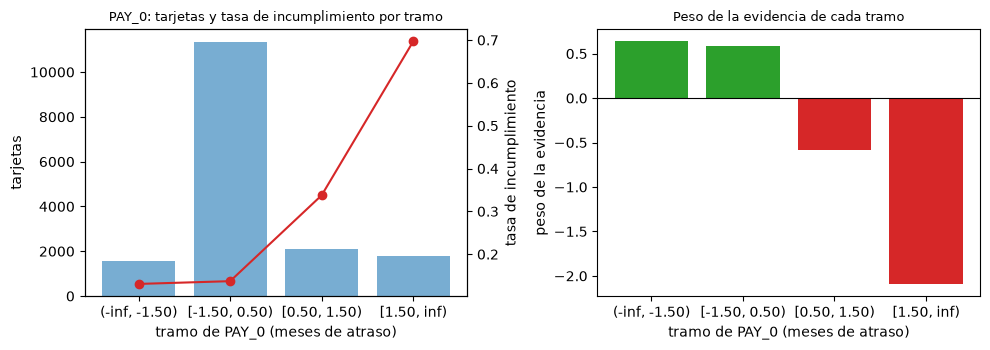

In [3]:
# WoE e IV de los tramos de PAY_0 desde sus conteos, junto a las tarjetas y la tasa de incumplimiento de cada tramo
pay0 = [r for r in table if r["feature"] == "PAY_0" and r["count"] > 0]
bins_ = [r["bin"] for r in pay0]
events = np.array([r["events"] for r in pay0], dtype=float)
non_events = np.array([r["count"] - r["events"] for r in pay0], dtype=float)
share_ne, share_e = non_events / non_events.sum(), events / events.sum()
woe = np.log(share_ne / share_e)
iv_bins = (share_ne - share_e) * woe
print("IV de PAY_0 desde los conteos:", round(float(iv_bins.sum()), 4), "|", "WoE de los tramos:", np.round(woe, 3))
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(bins_, events + non_events, color="tab:blue", alpha=0.6)
left.set_xlabel("tramo de PAY_0 (meses de atraso)")
left.set_ylabel("tarjetas")
rate_axis = left.twinx()
rate_axis.plot(bins_, events / (events + non_events), color="tab:red", marker="o")
rate_axis.set_ylabel("tasa de incumplimiento")
left.set_title("PAY_0: tarjetas y tasa de incumplimiento por tramo", fontsize=9)
right.bar(bins_, woe, color=np.where(woe > 0, "tab:green", "tab:red"))
right.axhline(0, color="black", linewidth=0.8)
right.set_xlabel("tramo de PAY_0 (meses de atraso)")
right.set_ylabel("peso de la evidencia")
right.set_title("Peso de la evidencia de cada tramo", fontsize=9)
fig.tight_layout()
plt.show()

Lee primero el panel izquierdo: las tarjetas se concentran en el segundo tramo (quienes pagaron a tiempo o renovaron), y la tasa de incumplimiento salta de cerca de 13% en los dos primeros tramos a cerca de 70% en el último, el de las tarjetas con dos o más meses de atraso. El panel derecho convierte esas tasas en evidencia. Los dos mejores tramos tienen un WoE positivo y el último un WoE cercano a -2, de modo que una tarjeta en él carga unas siete veces más evidencia de incumplimiento que la tarjeta promedio. El IV de 0,886 es grande: por convención, una variable sobre 0,5 se considera sospechosamente fuerte, y aquí es el historial de pago, que es tanto consecuencia como causa del incumplimiento. Lo que la figura no muestra es si los tramos se eligieron con las tarjetas correctas. Se ajustaron solo con las 16.800 tarjetas de entrenamiento, que es el tema del notebook 02.

### Paso 2: qué variables vale la pena conservar

El mismo IV puede leerse para cada variable. El ajuste conserva una variable solo si su IV alcanza 0,02, una convención de filtro atribuida a Siddiqi (2017) cuya página la investigación no pudo verificar; es una regla práctica, no un teorema. La siguiente celda dibuja el IV de las 20 variables del archivo desde el registro de la propia tarjeta de puntaje, en azul las 13 retenidas y en gris las 7 descartadas, frente al umbral.

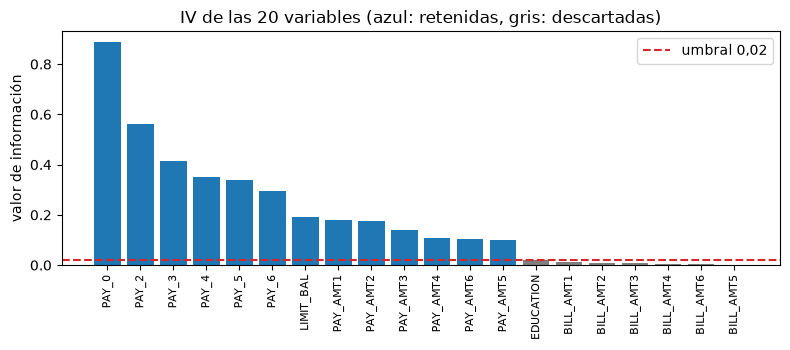

variables retenidas por el umbral 0,02: 13 / 20
PAY_0: 0.8862 | EDUCATION: 0.0189


In [4]:
# Dibujar el valor de información de cada variable frente al umbral de filtro de 0,02
ranked = sorted(card["iv"].items(), key=lambda item: -item[1])
names = [n for n, _ in ranked]
colors = ["tab:blue" if n in card["features"] else "tab:gray" for n in names]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(names, [v for _, v in ranked], color=colors)
ax.axhline(0.02, color="tab:red", linestyle="--", label="umbral 0,02")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.set_ylabel("valor de información")
ax.set_title("IV de las 20 variables (azul: retenidas, gris: descartadas)")
ax.legend()
fig.tight_layout()
plt.show()
print("variables retenidas por el umbral 0,02:", len(card["features"]), "/", len(ranked))
print("PAY_0:", round(card["iv"]["PAY_0"], 4), "| EDUCATION:", round(card["iv"]["EDUCATION"], 4))

Las seis variables de estado de pago dominan, seguidas del límite de crédito y los seis montos de pago. Los seis montos de facturación y el nivel educacional quedan bajo la línea: una vez conocido el estado de pago, aportan casi nada, y `EDUCATION` queda justo bajo el umbral. El gráfico dice además algo que el umbral oculta: las 13 variables retenidas no son 13 piezas independientes de evidencia, pues `PAY_0` a `PAY_6` describen el mismo comportamiento en meses consecutivos. Por eso importa el paso logístico de la siguiente sección, y por eso hay que revisar el signo de cada coeficiente.

### Paso 3: de la evidencia a los puntos

Un modelo logístico sobre el WoE de las variables retenidas entrega el logaritmo de las probabilidades relativas de incumplir, $\eta = \beta_0 + \sum_j \beta_j\,\mathrm{WoE}_j$. Como un WoE más alto significa menos riesgo, todos los coeficientes de una tarjeta de puntaje sana son negativos. Un escritorio no trabaja con ese logaritmo, así que el modelo se convierte en un puntaje lineal en el logaritmo de las probabilidades relativas de ser buen pagador, fijado por tres números: el puntaje de referencia (600), las probabilidades relativas de referencia, PR (50 a 1) y los puntos para duplicarlas, PDO = 20 (Siddiqi, 2017; la fórmula tal como la implementa `skorecard`, de ING, abierta):

$$\mathrm{Factor} = \frac{\mathrm{PDO}}{\ln 2}, \quad \mathrm{Offset} = \mathrm{Puntaje}_{ref} - \mathrm{Factor}\cdot\ln(\mathrm{PR}_{ref}), \quad \mathrm{Points}_{j,b} = \frac{\mathrm{Offset}}{k} - \left(\beta_j\,\mathrm{WoE}_{j,b} + \frac{\beta_0}{k}\right)\mathrm{Factor}.$$

El desplazamiento y el intercepto se reparten por igual entre las $k$ variables retenidas para que el puntaje sea una suma simple de puntos por tramo, y los puntos se redondean a enteros porque una tarjeta de puntaje es una tabla impresa. La siguiente celda calcula el factor y el desplazamiento desde los tres números de la escala, los puntos de los tramos de `PAY_0` desde su WoE con el coeficiente versionado, y dibuja los puntos de dos variables.

Factor y desplazamiento: 28.8539 487.1229
puntos de PAY_0, sin redondear y redondeados: [53.91 52.72 27.7  -4.6 ] [54 53 28 -5]


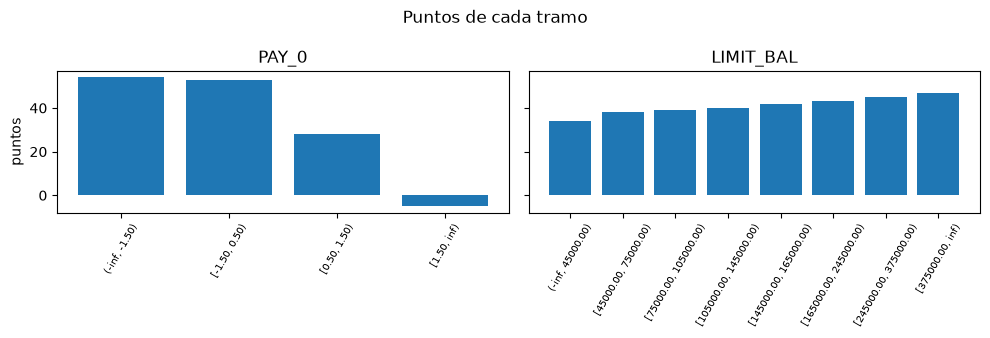

In [5]:
# Factor y desplazamiento desde los tres números de la escala, puntos de los tramos de PAY_0 y de dos variables
pdo, odds_ref, score_ref = 20.0, 50.0, 600.0
factor = pdo / np.log(2.0)
offset = score_ref - factor * np.log(odds_ref)
k, beta_0 = len(card["features"]), card["intercept"]
points_raw = offset / k - (card["coefficients"]["PAY_0"] * woe + beta_0 / k) * factor
print("Factor y desplazamiento:", round(float(factor), 4), round(float(offset), 4))
print("puntos de PAY_0, sin redondear y redondeados:", np.round(points_raw, 2), np.round(points_raw).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, name in zip(axes, ("PAY_0", "LIMIT_BAL")):
    rows = [r for r in table if r["feature"] == name and r["count"] > 0]
    ax.bar([r["bin"] for r in rows], [r["points"] for r in rows], color="tab:blue")
    ax.tick_params(axis="x", labelrotation=60, labelsize=7)
    ax.set_title(name)
axes[0].set_ylabel("puntos")
fig.suptitle("Puntos de cada tramo")
fig.tight_layout()
plt.show()

Los números de la escala resultan Factor 28,85 y desplazamiento 487,12, y los puntos sin redondear de los tramos de `PAY_0` (cerca de 54, 53, 28 y -5) se redondean a los enteros de la tabla impresa. La figura vuelve concreto el peso de cada variable: los tramos de `PAY_0` se reparten en casi 60 puntos, desde -5 para una tarjeta con dos o más meses de atraso hasta 54 para una que pagó a tiempo, mientras los tramos de `LIMIT_BAL` se reparten en 14 puntos. El puntaje de una tarjeta es la suma sobre 13 variables, de modo que un solo estado de pago atrasado puede moverla más que todos los tramos del límite de crédito juntos. Lo que la figura no muestra es el costo del redondeo, que miden los pasos siguientes.

### Paso 4: el puntaje es una suma y la PD puede leerse de vuelta desde él

Para puntuar una tarjeta se busca su tramo en cada variable y se suman los puntos. El archivo de la muestra reservada guarda 50 tarjetas con sus 13 columnas de puntos, su puntaje y la PD del modelo sin redondear. Como el puntaje es $\mathrm{Offset} - \mathrm{Factor}\,\eta$, la PD puede reconstruirse solo desde el puntaje entero: $\eta = (\mathrm{Offset} - \mathrm{Puntaje})/\mathrm{Factor}$ y $\mathrm{PD} = 1/(1 + e^{-\eta})$. La PD del modelo y la PD desde el puntaje difieren solo por el redondeo de los puntos, y la propiedad PDO dice que 20 puntos más deben reducir a la mitad las probabilidades relativas de incumplir. La siguiente celda suma los puntos de las 50 tarjetas, reconstruye la PD, revisa la duplicación en los puntajes 560 y 580 y dibuja las dos PD una contra otra.

mayor diferencia de PD en 50 tarjetas: 0.0084
razón de probabilidades relativas con 560 y 580 puntos: 2.0


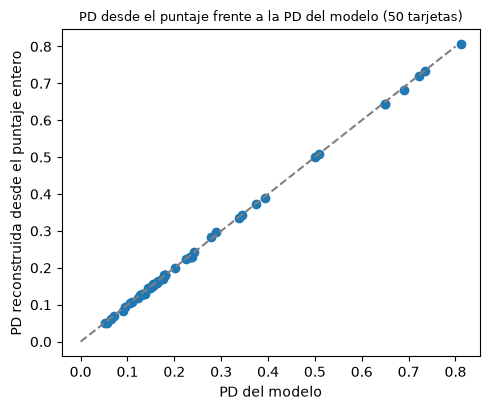

In [6]:
# Sumar los puntos de las 50 tarjetas, reconstruir la PD desde el puntaje entero y revisar la duplicación
y50 = np.array(sample["targets"])
score50 = np.array(sample["scorecard_points"]).sum(axis=1)
pd_model = np.array(sample["scorecard_pd"])
pd_points = 1.0 / (1.0 + np.exp(-(offset - score50) / factor))
print("mayor diferencia de PD en 50 tarjetas:", round(float(np.abs(pd_points - pd_model).max()), 4))
two = 1.0 / (1.0 + np.exp(-(offset - np.array([560.0, 580.0])) / factor))
odds_pair = two / (1.0 - two)
print("razón de probabilidades relativas con 560 y 580 puntos:", round(float(odds_pair[0] / odds_pair[1]), 3))
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(pd_model, pd_points, color="tab:blue")
ax.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--")
ax.set_xlabel("PD del modelo")
ax.set_ylabel("PD reconstruida desde el puntaje entero")
ax.set_title("PD desde el puntaje frente a la PD del modelo (50 tarjetas)", fontsize=9)
fig.tight_layout()
plt.show()

Las 50 tarjetas quedan sobre la diagonal, a lo más 0,008 de ella: redondear a enteros cada una de las 13 columnas de puntos mueve la PD de una tarjeta en menos de un punto porcentual, y la razón de las probabilidades relativas de incumplir con 560 y 580 puntos es exactamente 2, que es el significado de PDO = 20. La figura muestra el tamaño de la distorsión pero no su efecto sobre el orden, y el orden es lo primero por lo que se juzga una tarjeta de puntaje.

### Paso 5: ¿la tabla conserva el orden? El AUC y el KS del motor

La función `disc_auc` del motor recibe un valor de riesgo por tarjeta (más alto es más riesgoso) y el resultado 0/1, y devuelve el área bajo la curva ROC, la probabilidad de que un incumplidor quede clasificado como más riesgoso que un buen pagador, con su error estándar (Hanley y McNeil, 1982; BCE, 2019, anexo 1, sección 3.1). `disc_ks` devuelve la mayor distancia entre las distribuciones de puntaje de incumplidores y buenos pagadores, y `auc_with_variance` devuelve el AUC con su varianza y los conteos de incumplidores y buenos pagadores. La siguiente celda las llama sobre las 50 tarjetas dos veces, con la PD del modelo y con la PD reconstruida desde los puntos enteros, para ver si el redondeo cambia el orden.

In [7]:
# El motor sobre las 50 tarjetas: AUC, KS e intervalo de la PD del modelo, y AUC de la PD desde los puntos
auc_m = disc_auc(pd_model, y50, policy=policy, model_id="P1-scorecard")
auc_p = disc_auc(pd_points, y50, policy=policy, model_id="P1-scorecard")
ks_m = disc_ks(pd_model, y50, policy=policy, model_id="P1-scorecard")
auc_v, variance, n_def, n_good = auc_with_variance(pd_model, y50)
half = 1.96 * variance ** 0.5
print("AUC de la PD del modelo, 50 tarjetas:", round(auc_m.metric, 4))
print("intervalo de 95% del primero:", round(auc_v - half, 3), "-", round(auc_v + half, 3))
print("AUC de la PD reconstruida desde los puntos, 50 tarjetas:", round(auc_p.metric, 4))
print("KS de la PD del modelo, 50 tarjetas:", round(ks_m.metric, 4))

AUC de la PD del modelo, 50 tarjetas: 0.7752
intervalo de 95% del primero: 0.646 - 0.904
AUC de la PD reconstruida desde los puntos, 50 tarjetas: 0.7781
KS de la PD del modelo, 50 tarjetas: 0.5048


El AUC de la PD del modelo es 0,7752 y el de la PD reconstruida desde los puntos enteros es 0,7781: el redondeo no dañó el orden en estas tarjetas, incluso subió el AUC en 0,003, que es ruido a este tamaño. Más importante es el intervalo del primero, de 0,65 a 0,90. Con 15 incumplidores entre 50 tarjetas no se puede decir nada de la calidad de la tarjeta de puntaje, y por eso el siguiente paso pasa a las 9.000 tarjetas reservadas.

### Paso 6: el orden en 9.000 tarjetas reservadas

Las 9.000 tarjetas no están en el repositorio, pero el archivo de la muestra reservada versiona la curva CAP de la tarjeta de puntaje: la proporción acumulada de incumplidores detectados al cortar la población en pasos de 1% desde la tarjeta más riesgosa hacia abajo. Cada una de las 100 rebanadas contiene 90 tarjetas, y la proporción de incumplidores que contiene es el escalón de la curva. La siguiente celda reconstruye desde esos escalones un vector de 9.000 valores de riesgo y resultados, dando a cada tarjeta de una rebanada el mismo valor y a las rebanadas un orden decreciente, y se lo entrega al motor. El orden dentro de cada rebanada se pierde, así que las tarjetas de una rebanada cuentan como empates y el AUC resulta algo menor que el verdadero; el AUC versionado de las mismas tarjetas, calculado por la cadena de cálculo sobre las tarjetas mismas, se imprime al lado.

AUC en 9000 tarjetas, motor sobre tramos de 1%: 0.7586
AUC versionado para las mismas tarjetas: 0.7587
KS en 9000 tarjetas: 0.3956
razón de precisión en 9000 tarjetas: 0.5173


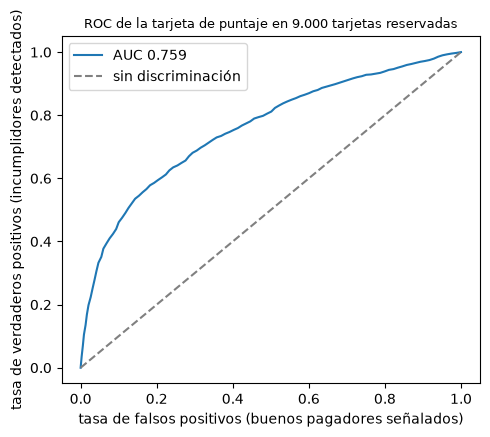

In [8]:
# Reconstruir 9000 tarjetas desde los escalones CAP (100 rebanadas de 90 tarjetas) y ejecutar el motor sobre ellas
cap = holdout["outputs"]["rungs"]["P1-scorecard"]["cap"]
n_cards, n_defaults = holdout["outputs"]["n"], holdout["outputs"]["defaults"]
defaults_per_slice = np.rint(np.diff(np.array(cap["defaults"])) * n_defaults).astype(int)
cards_per_slice = n_cards // len(defaults_per_slice)
risk9k = np.repeat(np.arange(len(defaults_per_slice), 0, -1), cards_per_slice)
flags = np.concatenate([np.r_[np.ones(d), np.zeros(cards_per_slice - d)] for d in defaults_per_slice])
auc9k = disc_auc(risk9k, flags, policy=policy, model_id="P1-scorecard")
ks9k = disc_ks(risk9k, flags, policy=policy, model_id="P1-scorecard")
committed_auc = next(t for t in holdout["tests"] if t["test_id"] == "disc.auc" and t["model_id"] == "P1-scorecard")
print("AUC en 9000 tarjetas, motor sobre tramos de 1%:", round(auc9k.metric, 4))
print("AUC versionado para las mismas tarjetas:", round(committed_auc["metric"], 4))
print("KS en 9000 tarjetas:", round(ks9k.metric, 4))
print("razón de precisión en 9000 tarjetas:", round(cap_accuracy_ratio(risk9k, flags), 4))
roc = holdout["outputs"]["rungs"]["P1-scorecard"]["roc"]
fig, ax = plt.subplots(figsize=(5, 4.4))
ax.plot(roc["fpr"], roc["tpr"], color="tab:blue", label=f"AUC {auc9k.metric:.3f}")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="sin discriminación")
ax.set_xlabel("tasa de falsos positivos (buenos pagadores señalados)")
ax.set_ylabel("tasa de verdaderos positivos (incumplidores detectados)")
ax.set_title("ROC de la tarjeta de puntaje en 9.000 tarjetas reservadas", fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()

El motor da un AUC de 0,7586 sobre las 9.000 tarjetas reconstruidas frente al 0,7587 versionado, de modo que lo que se pierde por tratar como empates las 90 tarjetas de una rebanada son dos diezmilésimas. Un KS de 0,3956 y una razón de precisión de 0,52 (el doble del AUC menos uno) dicen lo mismo en otras unidades: la tarjeta de puntaje separa con claridad a los incumplidores del resto, aunque lejos de la perfección. La curva ROC muestra de dónde viene la separación. Sube con fuerza a la izquierda, donde unos pocos por ciento de buenos pagadores señalados ya detectan una quinta parte de los incumplidores, y se aplana a la derecha. La curva no dice nada de si la PD tiene el tamaño correcto, solo del orden.

### Paso 7: los grados de la escala maestra y su calibración

Un banco ordena sus tarjetas en **grados** de significado igual, aquí los 12 grados de la escala maestra con cotas superiores $1\% \times 1{,}5^{k}$. Para cada grado el archivo de la muestra reservada versiona las tarjetas, los incumplimientos y la PD media, de modo que el motor puede preguntar si los incumplimientos que muestra el grado son compatibles con su PD. `pd_jeffreys_grades` ejecuta la prueba de Jeffreys de una cola (Brown, Cai y DasGupta, 2001) grado por grado, y `pd_chi2_grades` hace la pregunta por todos los grados a la vez con un estadístico chi cuadrado (BCBS, 2005). La siguiente celda ejecuta ambas sobre los ocho grados que contienen tarjetas y dibuja la PD media de cada grado junto a su tasa de incumplimiento observada.

chi cuadrado sobre grados, p: 0.0264 ámbar
grados con p menor que 0,05 en la prueba de Jeffreys: ['G08']


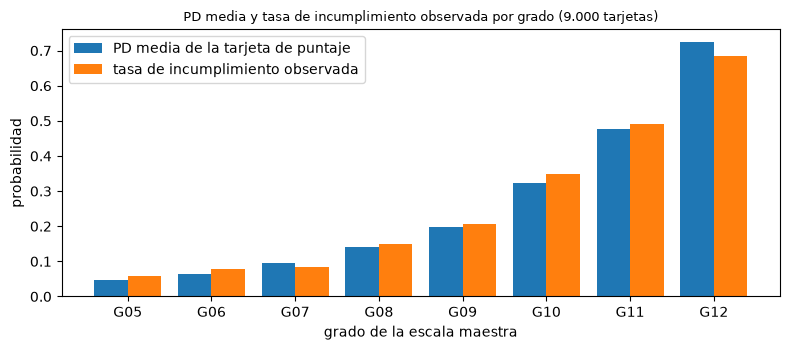

In [9]:
# Prueba de Jeffreys por grado y chi cuadrado sobre grados del motor, y PD media frente a tasa observada por grado
grades = [g for g in holdout["outputs"]["rungs"]["P1-scorecard"]["grades"] if g["n"] > 0]
n_g, d_g, pd_g = [g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades]
names_g = [g["grade"] for g in grades]
per_grade = pd_jeffreys_grades(n_g, d_g, pd_g, grades=names_g, policy=policy, model_id="P1-scorecard")
chi = pd_chi2_grades(n_g, d_g, pd_g, policy=policy, model_id="P1-scorecard", segment="portfolio")
flagged = [r.segment for r in per_grade if r.p_value < 0.05]
print("chi cuadrado sobre grados, p:", round(chi.p_value, 4), LIGHT[chi.light.value])
print("grados con p menor que 0,05 en la prueba de Jeffreys:", flagged)
x = np.arange(len(grades))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.2, pd_g, width=0.4, label="PD media de la tarjeta de puntaje")
ax.bar(x + 0.2, [g["dr"] for g in grades], width=0.4, label="tasa de incumplimiento observada")
ax.set_xticks(x, [g["grade"] for g in grades])
ax.set_xlabel("grado de la escala maestra")
ax.set_ylabel("probabilidad")
ax.set_title("PD media y tasa de incumplimiento observada por grado (9.000 tarjetas)", fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()

Las barras de las dos series suben juntas del grado G05 al G12, que es para lo que sirve una escala maestra, y son cercanas: la tasa observada queda algo sobre la PD media en los grados intermedios y bajo ella en el grado más riesgoso. El chi cuadrado sobre los grados tiene un valor p de 0,026, una luz ámbar, y la prueba de Jeffreys señala solo el grado G08, el mayor, con 3.101 tarjetas. Así, la tarjeta de puntaje es algo optimista en el centro de la escala, un hallazgo modesto que las pruebas de calibración del notebook 03 siguen. Haría falta un validador para llamarlo defecto; para este notebook es una medición.

## Resultados

**Respuesta:** Sí: una tabla impresa de puntos conserva casi todo el poder de orden del modelo del que proviene. La variable `PAY_0` sola lleva un valor de información de 0,8862, y 13 de las 20 variables alcanzan el umbral de 0,02. El factor es 28,8539 y el desplazamiento 487,1229, de modo que un puntaje es una simple suma de 13 puntos enteros. Redondear los puntos mueve la PD de una tarjeta en a lo más 0,0084 y la razón de las probabilidades relativas de incumplir con 20 puntos de diferencia es exactamente 2. En 50 tarjetas el AUC es 0,7752 con la PD del modelo y 0,7781 con la PD reconstruida desde los puntos, de modo que el redondeo no cuesta nada visible; el motor, ejecutado sobre 9.000 tarjetas reconstruidas desde los escalones CAP, da un AUC de 0,7586 frente al 0,7587 versionado, un KS de 0,3956 y una razón de precisión de 0,517. Por grados, el valor p del chi cuadrado es 0,0264 (ámbar) y solo un grado de ocho es señalado por la prueba de Jeffreys.

Lo que este notebook no muestra: cómo se ajustan los tramos y los coeficientes solo con las tarjetas de entrenamiento (notebook 02), cómo se compara la tarjeta de puntaje con modelos más simples y más ricos y cómo resiste una deriva (notebook 03), si sobrevive a un cambio de período (notebooks 04 y 07) o si supera a los retadores actuales (notebook 06). La muestra de 50 tarjetas es demasiado pequeña para juzgar la calidad, y las 9.000 tarjetas reconstruidas son la curva CAP versionada, no las tarjetas mismas.

## Resumen

- El peso de la evidencia compara la proporción de buenos pagadores y de incumplidores en un tramo, y el valor de información suma la diferencia sobre los tramos; `PAY_0` llega a 0,886 y 13 de 20 variables pasan el filtro de 0,02.
- Un modelo logístico sobre el WoE tiene coeficientes negativos cuando es sano; su intercepto y sus coeficientes se reparten por variable en una tabla de puntos, en una escala fijada por un puntaje de referencia, unas probabilidades relativas de referencia y el PDO.
- El puntaje es una suma de puntos enteros, la PD puede reconstruirse desde él sin el modelo, y el redondeo cuesta una diferencia pequeña y medible de PD, no un cambio de orden.
- El AUC, el KS y las pruebas por grado del motor juzgan la tabla sobre las tarjetas reservadas: ordena bien (AUC cercano a 0,76) y es algo optimista en los grados intermedios.

**Qué probar a continuación.** Cambia la variable del paso 1 de `PAY_0` a `LIMIT_BAL` y lee cómo difieren sus tramos y su IV; luego continúa con el notebook 02, que muestra cómo se ajustan los tramos y los coeficientes y por qué el ajuste debe ver solo las tarjetas de entrenamiento.

## Referencias

- Navas-Palencia, G. (2020), Optimal binning: mathematical programming formulation, sección 2.1 (WoE e IV). https://arxiv.org/abs/2001.08025
- Siddiqi, N. (2017), Intelligent Credit Scoring: Building and Implementing Better Credit Risk Scorecards, 2.ª ed., Wiley. https://doi.org/10.1002/9781119282396 (la fórmula de la escala se verifica en la implementación abierta, `skorecard` de ING, https://github.com/ing-bank/skorecard/blob/main/skorecard/rescale/rescale.py; la página del libro de la fórmula y del umbral 0,02 está SIN VERIFICAR en la investigación.)
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients